# EDA: RoomSense train/test

train = วันที่ 1–3, test = วันที่ 4 · 2 Hz · label `power_on`

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
df = pd.concat([pd.read_csv("../../data/train.csv").assign(split="train"),
                pd.read_csv("../../data/test.csv").assign(split="test")], ignore_index=True)
df.shape

(86384, 17)

## ค่าที่หายไป
`nan` = DHT22 อ่านไม่ได้, `person_count = -1` = กล้องไม่ส่งข้อมูล

In [2]:
pd.DataFrame({"nan": df.isna().sum(), "-1": (df == -1).sum()}).query("nan > 0 or `-1` > 0")

,nan,-1
temp_c,168,0
humidity,168,0
temp_f,168,0
heat_index_c,168,0
heat_index_f,168,0
person_count,0,249


## label ต่อวัน

In [3]:
df.groupby(["split", "day"]).agg(rows=("power_on", "size"), power_on=("power_on", "mean"), boots=("boot", "nunique"))

rows  power_on  boots
split day                        
test  4    21597  0.600639      1
train 1    20998  0.618297      1
      2    22191  0.650264      2
      3    21598  0.561858      1

## สถิติแยก train/test

In [4]:
S = ["mq2_raw", "temp_c", "humidity", "analog_1_raw", "analog_2_raw", "person_count"]
df.replace({"person_count": {-1: np.nan}}).groupby("split")[S].describe().T.unstack(0).round(1)

split     test                                                           \
       mq2_raw   temp_c humidity analog_1_raw analog_2_raw person_count   
count  21597.0  21565.0  21565.0      21597.0      21597.0      21512.0   
mean     364.0     31.0     63.0        469.2        368.0          1.7   
std      115.0      0.8      2.1        242.0        304.9          1.6   
min      321.0     28.6     59.7        211.0        286.0          0.0   
25%      339.0     30.6     61.4        268.0        307.0          0.0   
50%      346.0     31.2     62.3        280.0        317.0          2.0   
75%      351.0     31.4     64.6        716.0        346.0          3.0   
max     1847.0     32.3     70.3       1015.0       3297.0          6.0   

split    train                                                           
       mq2_raw   temp_c humidity analog_1_raw analog_2_raw person_count  
count  64787.0  64651.0  64651.0      64787.0      64787.0      64623.0  
mean     337.7     29.7     55.1        545.5        343.3          1.4  
std       86.4      2.1      4.0        324.5        278.0          1.5  
min      289.0     25.8     49.0        229.0        282.0          0.0  
25%      308.0     27.8     51.4        279.0        301.0          0.0  
50%      323.0     28.7     54.2        288.0        308.0          1.0  
75%      347.0     32.1     58.6        915.0        313.0          3.0  
max     1836.0     33.2     66.4       1201.0       3295.0          6.0

## เซนเซอร์แยกตาม label

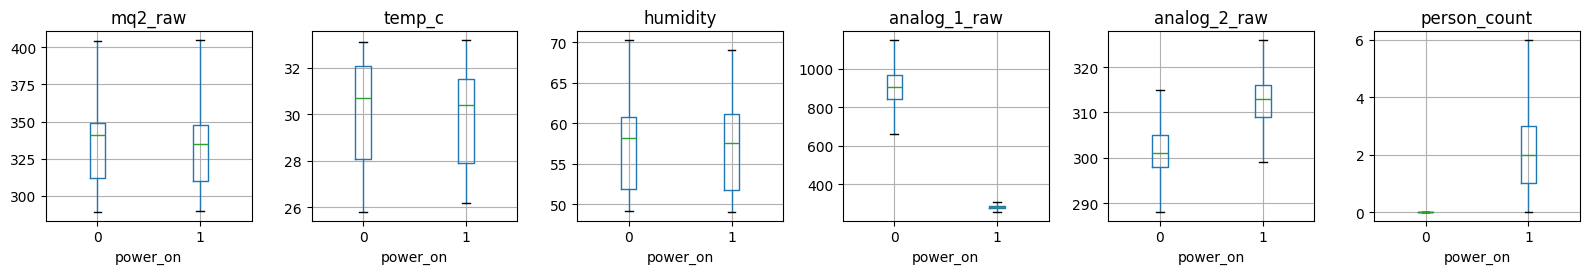

In [5]:
d = df.replace({"person_count": {-1: np.nan}})
fig, ax = plt.subplots(1, len(S), figsize=(16, 3))
for a, c in zip(ax, S):
    d.boxplot(c, by="power_on", ax=a, showfliers=False); a.set_title(c); a.set_xlabel("power_on")
plt.suptitle(""); plt.tight_layout()

## correlation กับ label

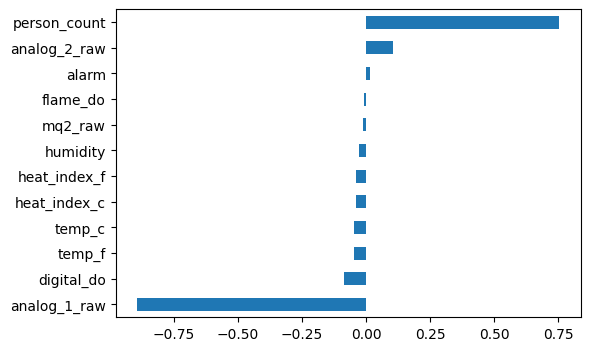

In [6]:
num = d.drop(columns=["split", "day", "boot", "timestamp_ms"])
num.corr()["power_on"].drop("power_on").sort_values().plot.barh(figsize=(6, 4));

## timeline วันที่ 1

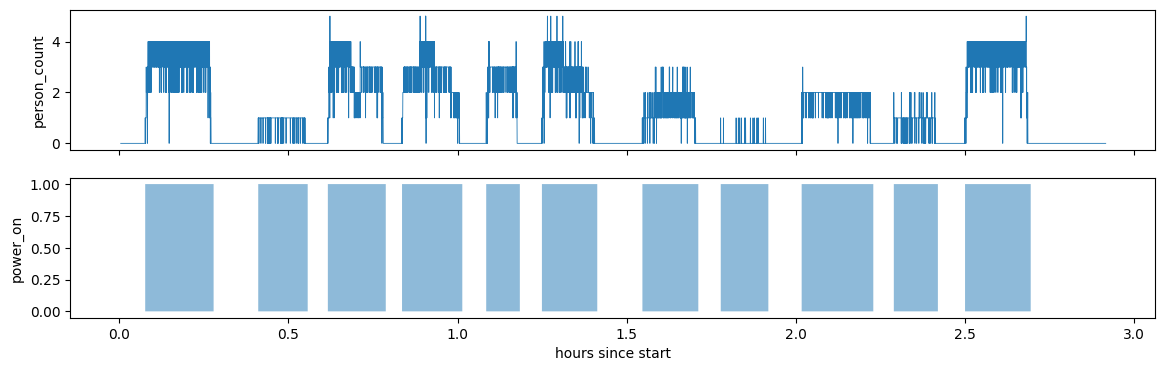

In [7]:
x = d[d.day == 1]
t = np.arange(len(x)) / 7200                         # ชั่วโมงนับจากเริ่ม (2 Hz)
fig, ax = plt.subplots(2, 1, figsize=(14, 4), sharex=True)
ax[0].plot(t, x.person_count, lw=.6); ax[0].set_ylabel("person_count")
ax[1].fill_between(t, x.power_on, step="mid", alpha=.5); ax[1].set_ylabel("power_on"); ax[1].set_xlabel("hours since start");

## train vs test: flame / alarm
วันที่ 4 มีแดดส่องเป็นช่วง ๆ ดูว่า `flame_do = 0` และ `alarm` ต่างจาก train ไหม

In [8]:
df.groupby("day").agg(flame_rows=("flame_do", lambda s: (s == 0).sum()), alarm_rows=("alarm", "sum"), mq2_max=("mq2_raw", "max"))

,flame_rows,alarm_rows,mq2_max
day,,,
1,14,318,1836
2,18,93,849
3,0,264,1460
4,37,415,1847
